<a href="https://colab.research.google.com/github/nilesh-r-dev/TNS_T170800502_AIML/blob/main/tns_day_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import shutil
import zipfile
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()

json_file = next((f for f in uploaded if f.endswith('.json')), None)

if json_file is None:
    raise FileNotFoundError("Please upload your Kaggle JSON file.")

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy(json_file, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!pip install -q kaggle openpyxl

!kaggle datasets download -d krantiswalke/bank-personal-loan-modelling -p /content

with zipfile.ZipFile('/content/bank-personal-loan-modelling.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/data')

csv_files = glob.glob('/content/data/**/*.csv', recursive=True)
excel_files = glob.glob('/content/data/**/*.xlsx', recursive=True)

if csv_files:
    df = pd.read_csv(csv_files[0])
elif excel_files:
    df = pd.read_excel(excel_files[0])
else:
    raise FileNotFoundError("No CSV or Excel file found.")

print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/krantiswalke/bank-personal-loan-modelling
License(s): unknown
100% 60.6k/60.6k [00:00<00:00, 13.6MB/s]

   ID  Age  Experience  Income  ZIP Code  Family  CCAvg  Education  Mortgage  \
0   1   25           1      49     91107       4    1.6          1         0   
1   2   45          19      34     90089       3    1.5          1         0   
2   3   39          15      11     94720       1    1.0          1         0   
3   4   35           9     100     94112       1    2.7          2         0   
4   5   35           8      45     91330       4    1.0          2         0   

   Personal Loan  Securities Account  CD Account  Online  CreditCard  
0              0                   1           0       0           0  
1              0                   1           0       0           0  
2              0                   0           0       0           0  
3              0                   0           0    

In [3]:
df.tail()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


In [ ]:
df.describe()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [4]:
print("Shape:", df.shape)

Shape: (5000, 14)


In [ ]:
df.isnull().sum()

,0
ID,0
Age,0
Experience,0
Income,0
ZIP Code,0
Family,0
CCAvg,0
Education,0
Mortgage,0
Personal Loan,0


In [5]:
df = df.drop_duplicates()

In [ ]:
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

df.columns = df.columns.str.strip()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Cleaned shape:", df.shape)

display(df.head())


Missing values after cleaning:
ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

Duplicate rows: 0
Cleaned shape: (5000, 14)


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


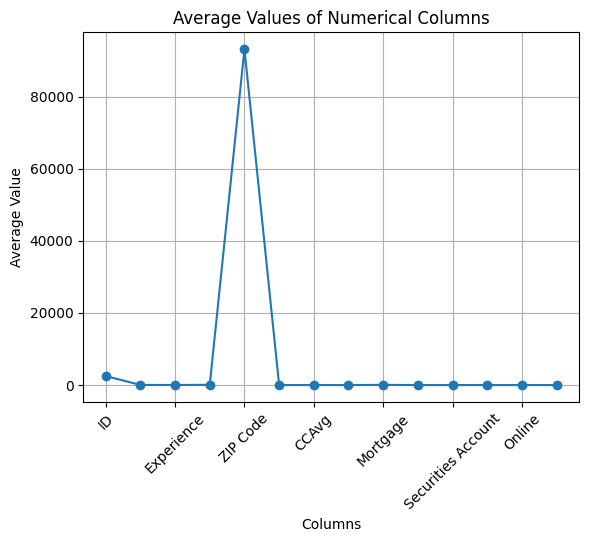

In [6]:
df.select_dtypes(include='number').mean().plot(kind='line', marker='o')
plt.title('Average Values of Numerical Columns')
plt.xlabel('Columns')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

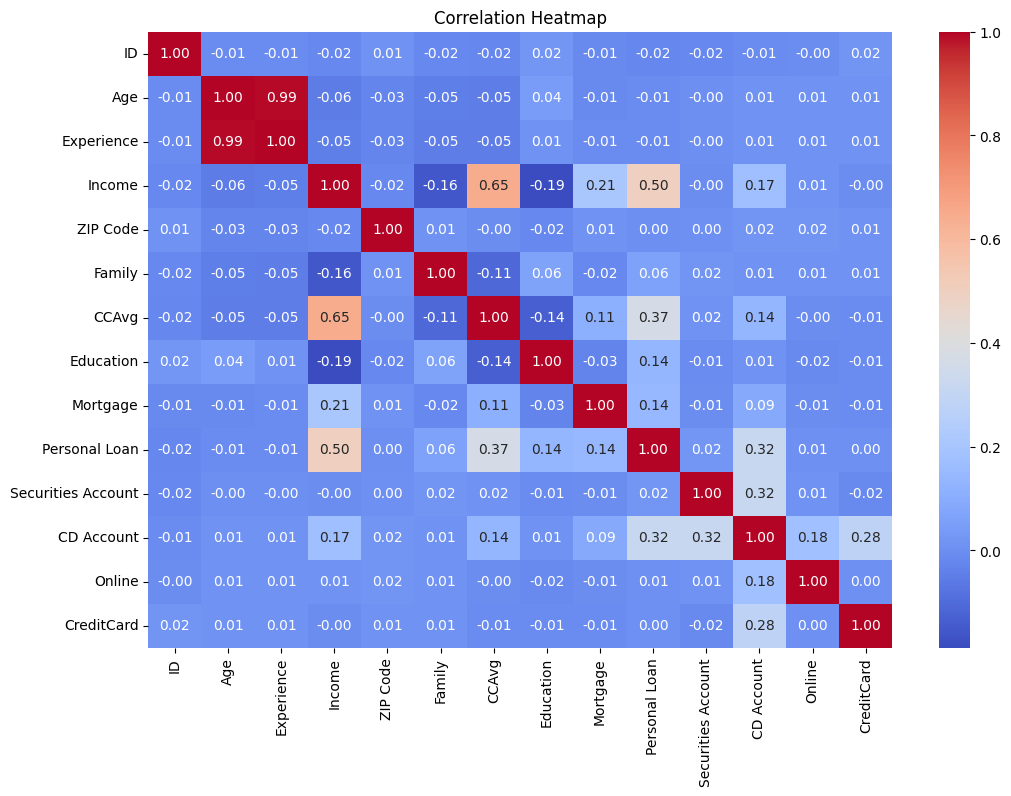

In [7]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

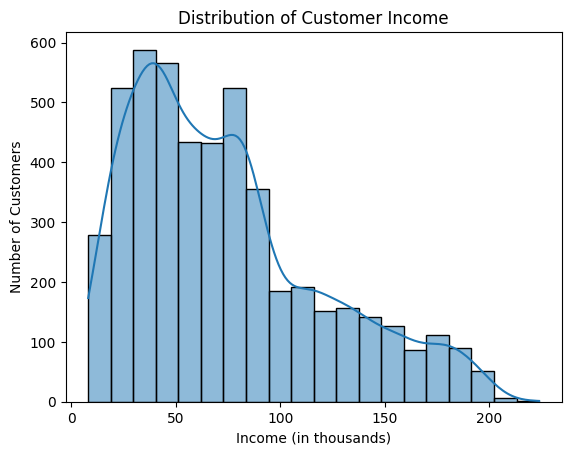

In [8]:
sns.histplot(data=df, x='Income', bins=20, kde=True)

plt.title('Distribution of Customer Income')
plt.xlabel('Income (in thousands)')
plt.ylabel('Number of Customers')
plt.show()

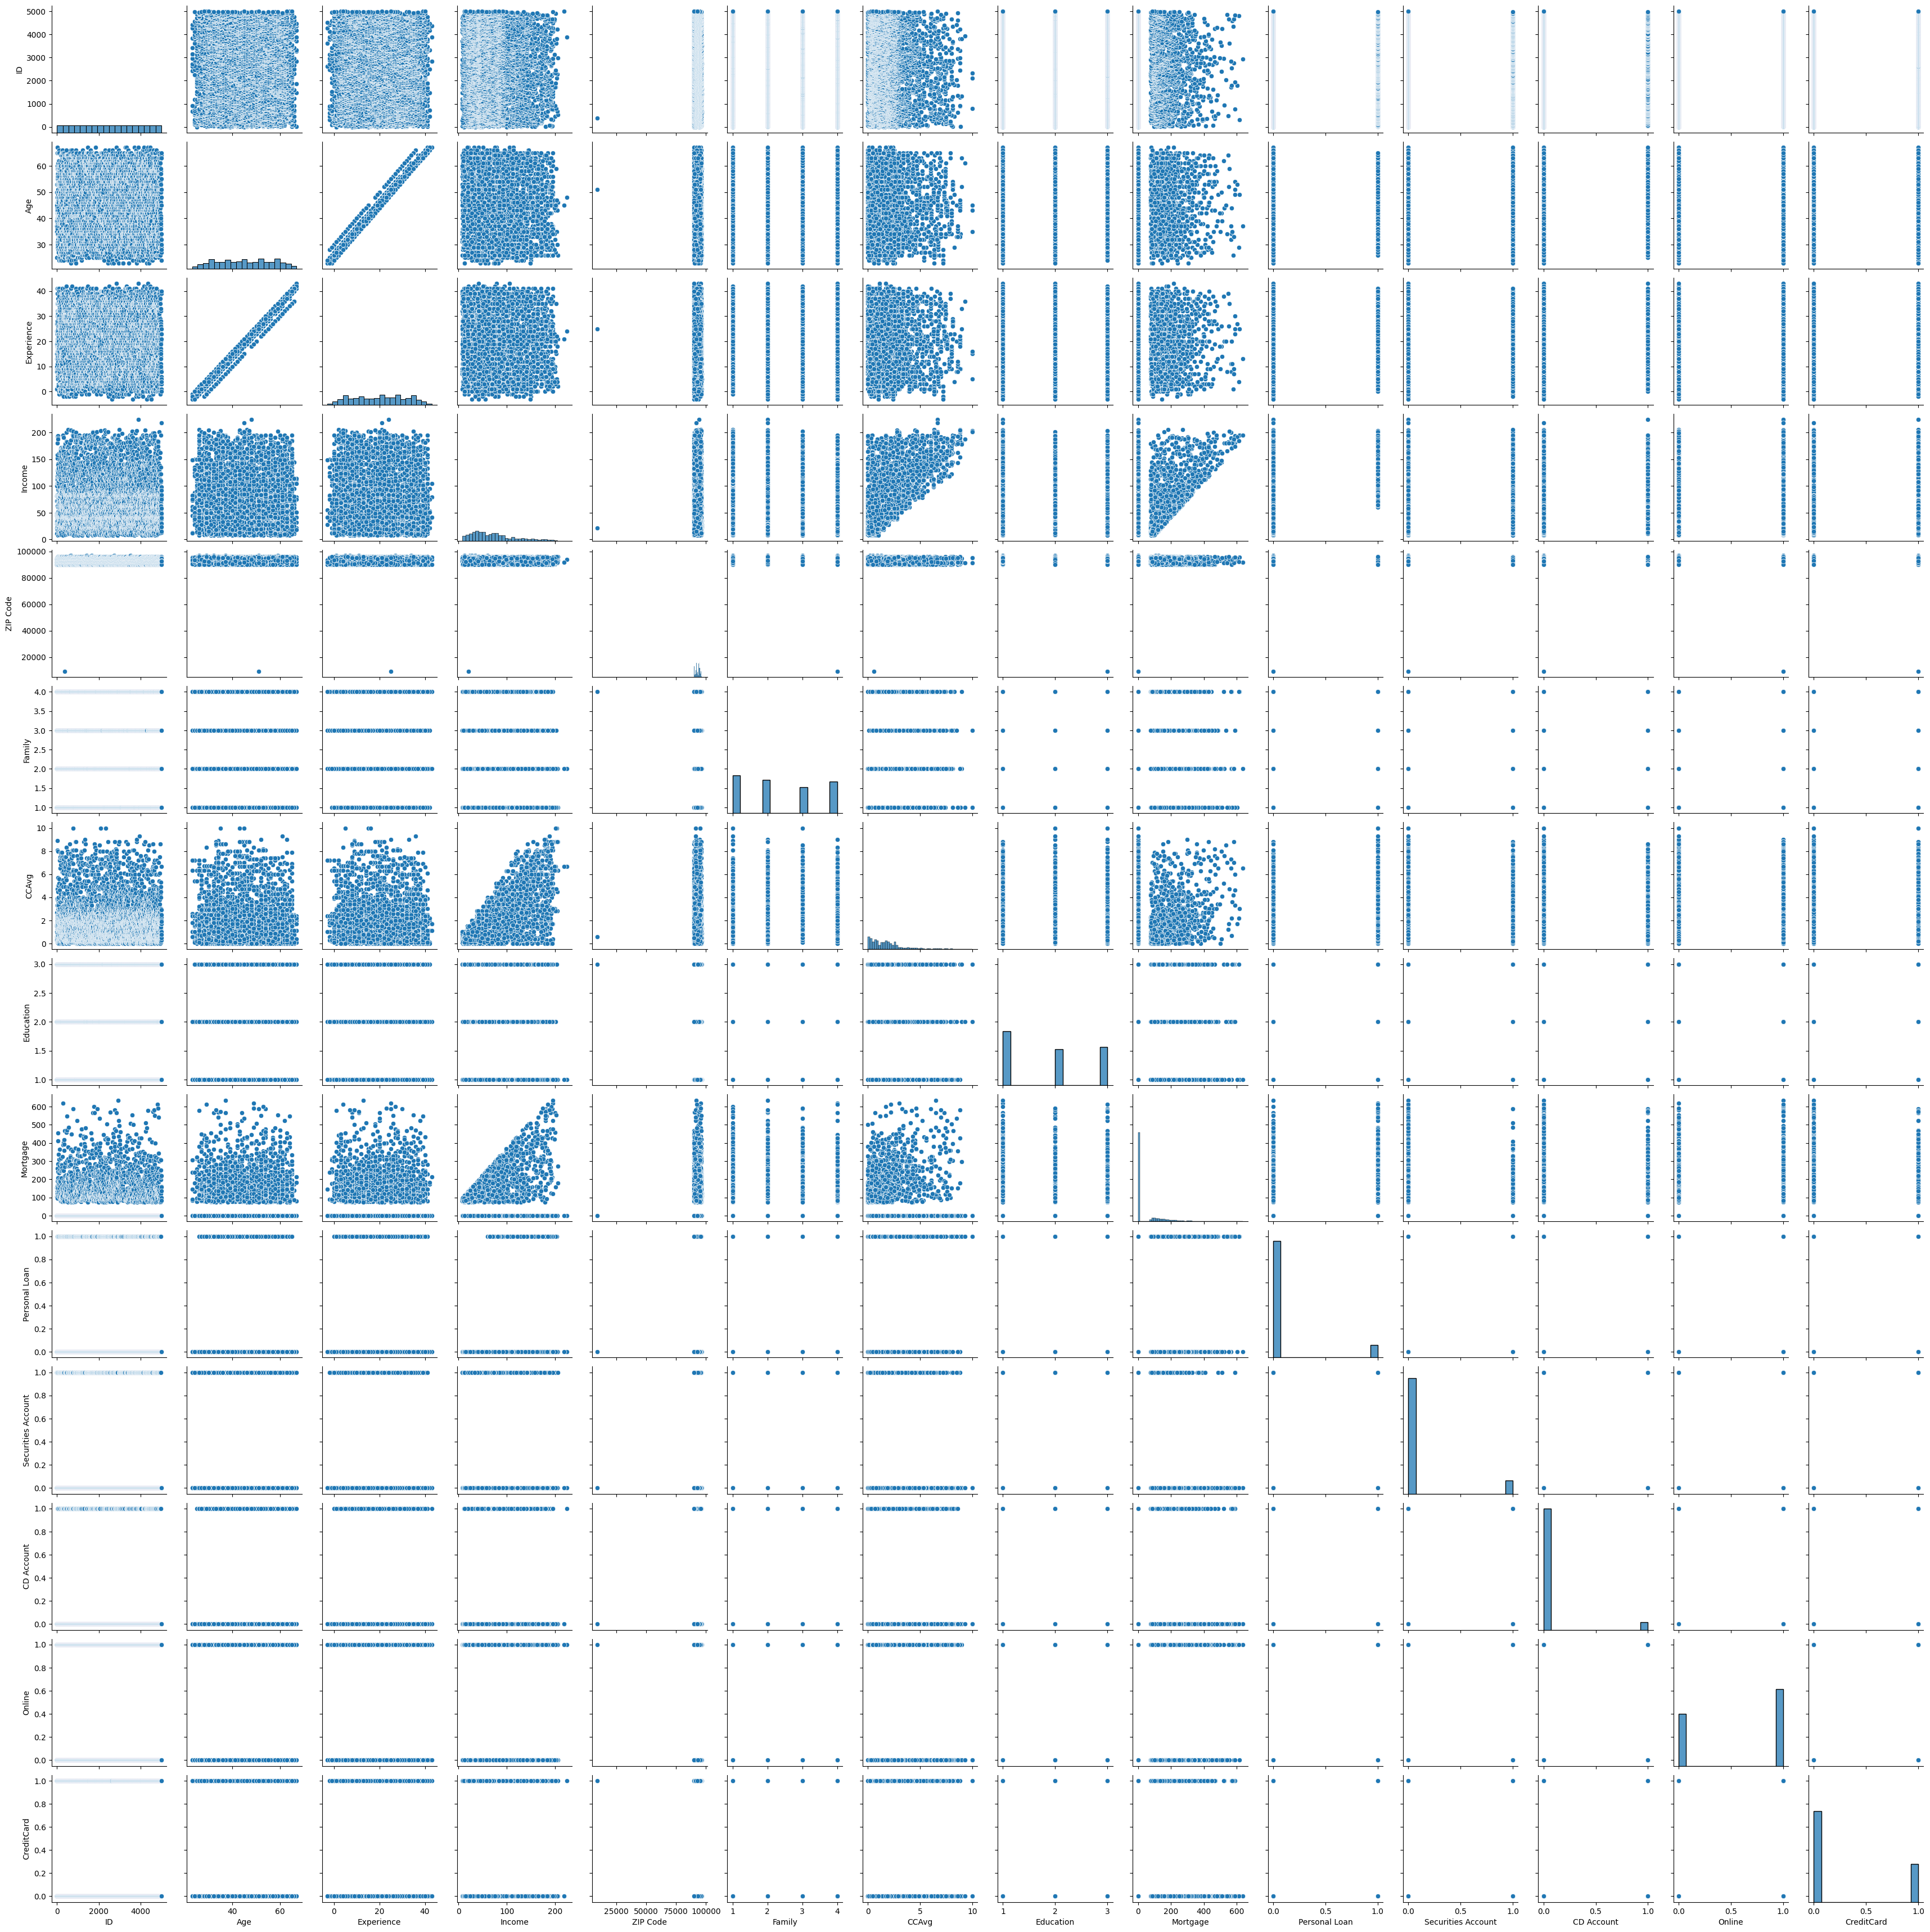

In [9]:
sns.pairplot(df)
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [11]:
X = df.drop(columns=['Personal Loan', 'ID', 'ZIP Code'], errors='ignore')
y = df['Personal Loan']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Features shape: (5000, 11)
Target shape: (5000,)
Personal Loan
0    4520
1     480
Name: count, dtype: int64


In [12]:
X = pd.get_dummies(X, drop_first=True)

X = X.fillna(X.median())

print(X.head())
print("Features after encoding:", X.shape)

   Age  Experience  Income  Family  CCAvg  Education  Mortgage  \
0   25           1      49       4    1.6          1         0   
1   45          19      34       3    1.5          1         0   
2   39          15      11       1    1.0          1         0   
3   35           9     100       1    2.7          2         0   
4   35           8      45       4    1.0          2         0   

   Securities Account  CD Account  Online  CreditCard  
0                   1           0       0           0  
1                   1           0       0           0  
2                   0           0       0           0  
3                   0           0       0           0  
4                   0           0       0           1  
Features after encoding: (5000, 11)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 11)
Testing data: (1000, 11)


In [14]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


In [15]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)



LogisticRegression(max_iter=1000)

In [16]:
y_pred = log_model.predict(X_test)

y_prob = log_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("First 10 probabilities:")
print(y_prob[:10])

First 10 predictions:
[0 1 0 0 0 0 0 0 0 0]
First 10 probabilities:
[1.54012664e-04 8.79201873e-01 1.75806595e-04 2.97185052e-02
 8.73399956e-03 6.06198840e-03 9.84557542e-04 1.97320968e-03
 8.99196601e-02 3.39069763e-02]


In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000



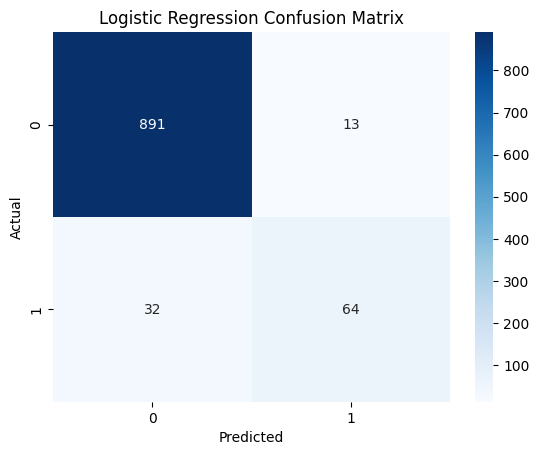

In [18]:

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
import pandas as pd

df.columns = df.columns.str.strip()
df = df.drop_duplicates()
df = df.dropna(subset=['Personal Loan'])

X = df.drop(columns=['Personal Loan', 'ID', 'ZIP Code'], errors='ignore')
y = df['Personal Loan']

X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median())

print("Data prepared successfully")
print("Features:", X.shape)
print("Target:", y.shape)

Data prepared successfully
Features: (5000, 11)
Target: (5000,)


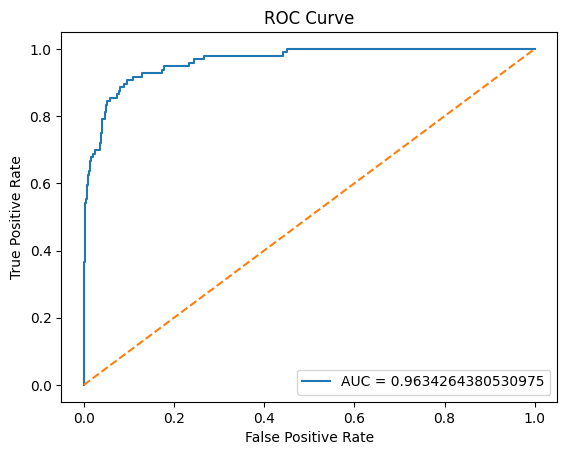

In [20]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = " + str(roc_auc))
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [21]:
# Get coefficients
coeff_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_model.coef_[0]
})

coeff_df.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
2,Income,2.391154
5,Education,1.428315
8,CD Account,0.935894
3,Family,0.732153
1,Experience,0.396314
4,CCAvg,0.234642
6,Mortgage,0.068060
7,Securities Account,-0.284907
9,Online,-0.332574
0,Age,-0.338009


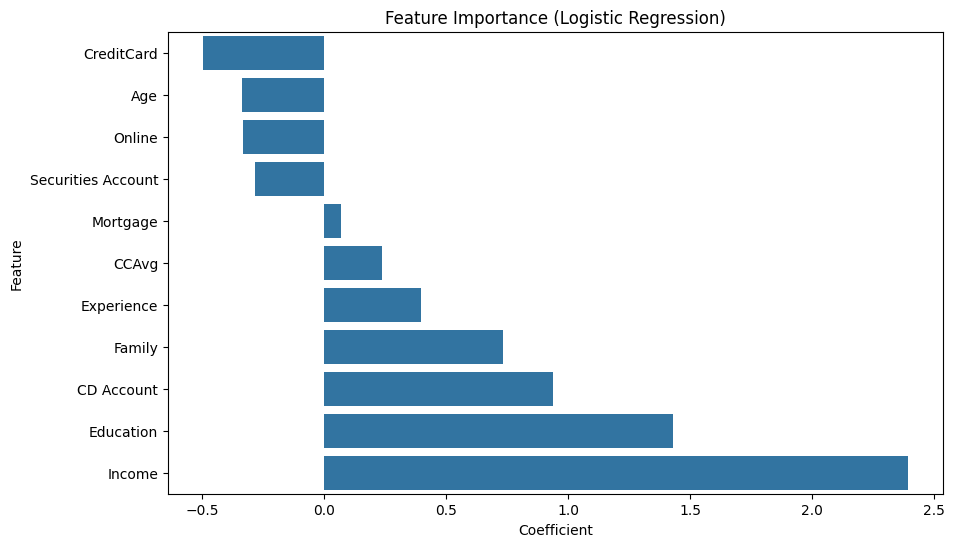

In [22]:
plt.figure(figsize=(10,6))
sns.barplot(x='Coefficient', y='Feature', data=coeff_df.sort_values(by='Coefficient'))
plt.title("Feature Importance (Logistic Regression)")
plt.show()

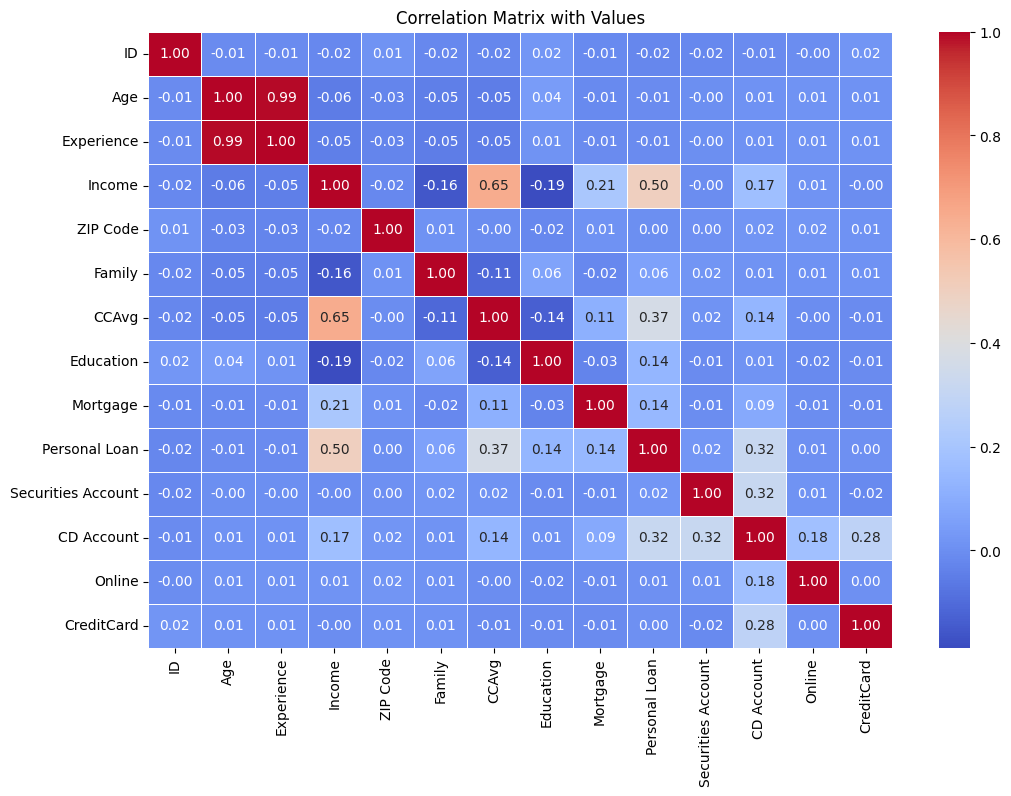

In [23]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,        # 👉 shows numbers
    fmt=".2f",         # 👉 2 decimal places
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Correlation Matrix with Values")
plt.show()

In [24]:
# L2 Regularization (default)
log_model_l2 = LogisticRegression(penalty='l2')
log_model_l2.fit(X_train, y_train)

# L1 Regularization
log_model_l1 = LogisticRegression(penalty='l1', solver='liblinear')
log_model_l1.fit(X_train, y_train)

LogisticRegression(penalty='l1', solver='liblinear')

In [25]:
from sklearn.metrics import accuracy_score

print("L2 Accuracy:", accuracy_score(y_test, log_model_l2.predict(X_test)))
print("L1 Accuracy:", accuracy_score(y_test, log_model_l1.predict(X_test)))

L2 Accuracy: 0.955
L1 Accuracy: 0.954


In [26]:
from sklearn.metrics import classification_report

# Predictions (already done, but safe to include)
y_pred_multi = log_model.predict(X_test)

# Classification Report
print("Classification Report (Multivariate Logistic Regression):\n")
print(classification_report(y_test, y_pred_multi))

Classification Report (Multivariate Logistic Regression):

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000



In [27]:
# Check feature order
X.columns

Index(['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education',
       'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard'],
      dtype='object')

In [28]:
# Example: [Age, Experience, Income, ZIP Code, Family, CCAvg, Education, Mortgage, Securities Account, CD Account, Online, CreditCard]

sample = [[45, 20, 60, 400001, 2, 1.5, 2, 0, 1, 0, 1, 0]]

In [31]:
# Create a sample customer
sample = pd.DataFrame([{
    'Age': 35,
    'Experience': 10,
    'Income': 80,
    'Family': 3,
    'CCAvg': 2.0,
    'Education': 2,
    'Mortgage': 0,
    'Securities Account': 0,
    'CD Account': 0,
    'Online': 1,
    'CreditCard': 0
}])

# Predict loan acceptance
prediction = log_model.predict(sample)

# Predict probability of loan acceptance
probability = log_model.predict_proba(sample)[0][1]

print("Predicted Class:", prediction[0])
print("Probability of Loan Acceptance:", round(probability * 100, 2), "%")

if prediction[0] == 1:
    print("Customer is likely to accept the personal loan.")
else:
    print("Customer is unlikely to accept the personal loan.")

Predicted Class: 1
Probability of Loan Acceptance: 100.0 %
Customer is likely to accept the personal loan.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [33]:
# Predict loan acceptance
prediction = log_model.predict(sample)

# Predict probability
probability = log_model.predict_proba(sample)[0][1]

# Display output
print("Predicted Class:", prediction[0])
print("Probability of Loan Acceptance:", round(probability * 100, 2), "%")

Predicted Class: 1
Probability of Loan Acceptance: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [35]:
from sklearn.metrics import classification_report

# Predictions (already done, but safe to include)
y_pred_multi = log_model.predict(X_test)

# Classification Report
print("Classification Report (Multivariate Logistic Regression):\n")
print(classification_report(y_test, y_pred_multi))

Classification Report (Multivariate Logistic Regression):

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000



In [36]:
# Check feature order
X.columns

Index(['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education',
       'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard'],
      dtype='object')

In [37]:
# Example: [Age, Experience, Income, ZIP Code, Family, CCAvg, Education, Mortgage, Securities Account, CD Account, Online, CreditCard]

sample = [[45, 20, 60, 400001, 2, 1.5, 2, 0, 1, 0, 1, 0]]

In [39]:
# Create sample customer
sample = pd.DataFrame([{
    'Age': 35,
    'Experience': 10,
    'Income': 80,
    'Family': 3,
    'CCAvg': 2.0,
    'Education': 2,
    'Mortgage': 0,
    'Securities Account': 0,
    'CD Account': 0,
    'Online': 1,
    'CreditCard': 0
}])

# Predict loan acceptance
prediction = log_model.predict(sample)

# Calculate probability
probability = log_model.predict_proba(sample)[0][1]

# Display results
print("Predicted Class:", prediction[0])
print("Probability of Loan Acceptance:", round(probability * 100, 2), "%")

Predicted Class: 1
Probability of Loan Acceptance: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [40]:
if prediction[0] == 1:
    print(f"Customer is LIKELY to accept the loan (Confidence: {probability:.2f})")
else:
    print(f"Customer is NOT likely to accept the loan (Confidence: {1 - probability:.2f})")

Customer is LIKELY to accept the loan (Confidence: 1.00)


In [45]:

# Take user input and predict personal loan acceptance
import pandas as pd

age = float(input("Enter Age: "))
experience = float(input("Enter Experience: "))
income = float(input("Enter Income (in thousands): "))
family = int(input("Enter Family size (1-4): "))
ccavg = float(input("Enter CCAvg (in thousands): "))
education = int(input("Enter Education (1/2/3): "))
mortgage = float(input("Enter Mortgage: "))
securities = int(input("Securities Account (0/1): "))
cd = int(input("CD Account (0/1): "))
online = int(input("Online (0/1): "))
credit = int(input("Credit Card (0/1): "))

# Create input DataFrame in training column order
user_input = pd.DataFrame([{
    'Age': age,
    'Experience': experience,
    'Income': income,
    'Family': family,
    'CCAvg': ccavg,
    'Education': education,
    'Mortgage': mortgage,
    'Securities Account': securities,
    'CD Account': cd,
    'Online': online,
    'CreditCard': credit
}])

# Predict using the trained pipeline OR separate scaler/model
# If log_model is a pipeline containing StandardScaler:
prediction = log_model.predict(user_input)
probability = log_model.predict_proba(user_input)[0][1]

# Display results
print("\n--- Loan Prediction Result ---")
if prediction[0] == 1:
    print("Prediction: Customer may accept the personal loan.")
else:
    print("Prediction: Customer may not accept the personal loan.")

print("Probability of acceptance:", round(probability * 100, 2), "%")


Enter Age: 22
Enter Experience: 2
Enter Income (in thousands): 1566486
Enter Family size (1-4): 4
Enter CCAvg (in thousands): 84
Enter Education (1/2/3): 3
Enter Mortgage: 0
Securities Account (0/1): 1
CD Account (0/1): 1
Online (0/1): 0
Credit Card (0/1): 0

--- Loan Prediction Result ---
Prediction: Customer may accept the personal loan.
Probability of acceptance: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [46]:
from sklearn.svm import SVC  #support vector classifier

svm_linear = SVC(kernel='linear', probability=True)

svm_linear.fit(X_train, y_train)

SVC(kernel='linear', probability=True)

In [47]:
svm_rbf = SVC(kernel='rbf', probability=True)

svm_rbf.fit(X_train, y_train)

SVC(probability=True)

In [48]:
y_pred_svm = svm_rbf.predict(X_test)
y_prob_svm = svm_rbf.predict_proba(X_test)[:,1]


In [49]:
from sklearn.metrics import accuracy_score

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.978


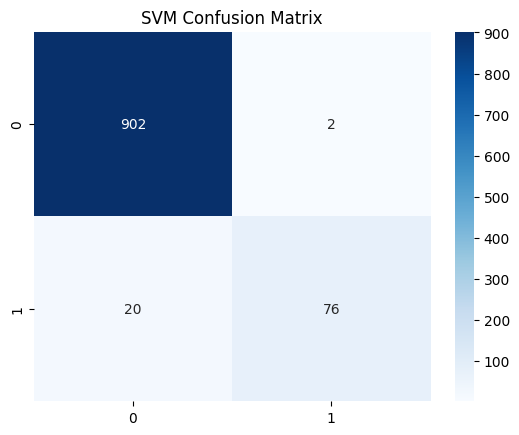

In [50]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("SVM Confusion Matrix")
plt.show()

In [51]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       904
           1       0.97      0.79      0.87        96

    accuracy                           0.98      1000
   macro avg       0.98      0.89      0.93      1000
weighted avg       0.98      0.98      0.98      1000



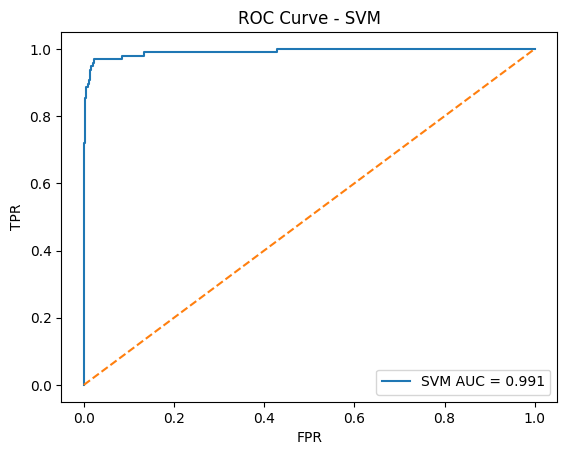

In [52]:
from sklearn.metrics import roc_curve, auc

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = auc(fpr_svm, tpr_svm)

plt.plot(fpr_svm, tpr_svm, label=f"SVM AUC = {auc_svm:.3f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()

In [54]:
# Q1. Select features for PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df.drop(columns=['Personal Loan', 'ID', 'ZIP Code'])
print(X.head())


   Age  Experience  Income  Family  CCAvg  Education  Mortgage  \
0   25           1      49       4    1.6          1         0   
1   45          19      34       3    1.5          1         0   
2   39          15      11       1    1.0          1         0   
3   35           9     100       1    2.7          2         0   
4   35           8      45       4    1.0          2         0   

   Securities Account  CD Account  Online  CreditCard  
0                   1           0       0           0  
1                   1           0       0           0  
2                   0           0       0           0  
3                   0           0       0           0  
4                   0           0       0           1  


In [55]:
# Q2. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.77441684 -1.66607847 -0.53822878  1.39741398 -0.19338544 -1.04907792
  -0.55552393  2.92891517 -0.25354028 -1.21661774 -0.64531434]
 [-0.02952359 -0.09633022 -0.8641094   0.52599094 -0.25061056 -1.04907792
  -0.55552393  2.92891517 -0.25354028 -1.21661774 -0.64531434]
 [-0.55299157 -0.44516316 -1.36379301 -1.21685513 -0.53673618 -1.04907792
  -0.55552393 -0.34142334 -0.25354028 -1.21661774 -0.64531434]
 [-0.90197022 -0.96841258  0.56976533 -1.21685513  0.43609092  0.14170292
  -0.55552393 -0.34142334 -0.25354028 -1.21661774 -0.64531434]
 [-0.90197022 -1.05562082 -0.62513027  1.39741398 -0.53673618  0.14170292
  -0.55552393 -0.34142334 -0.25354028 -1.21661774  1.54963239]]


In [56]:
# Q3. Apply PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(X_pca[:5])

[[-2.00207918 -1.63521739]
 [ 0.14781091 -0.55826806]
 [-0.08411657 -1.2549175 ]
 [-1.36242594 -0.26753379]
 [-0.711365   -1.75996152]]


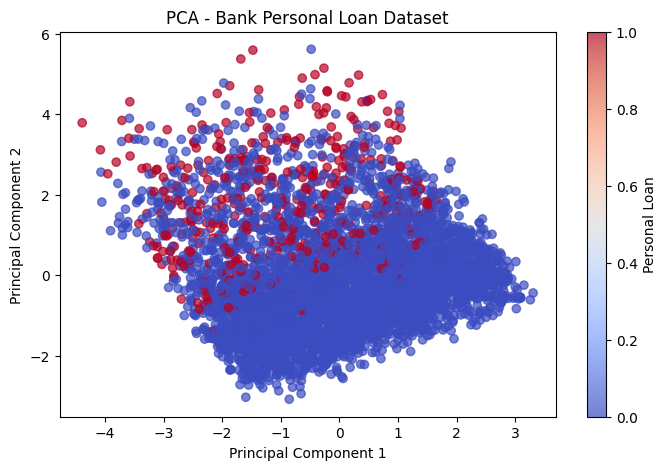

In [57]:
# Q4. Plot PCA results
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Personal Loan'],
    cmap='coolwarm',
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Bank Personal Loan Dataset')
plt.colorbar(label='Personal Loan')
plt.show()

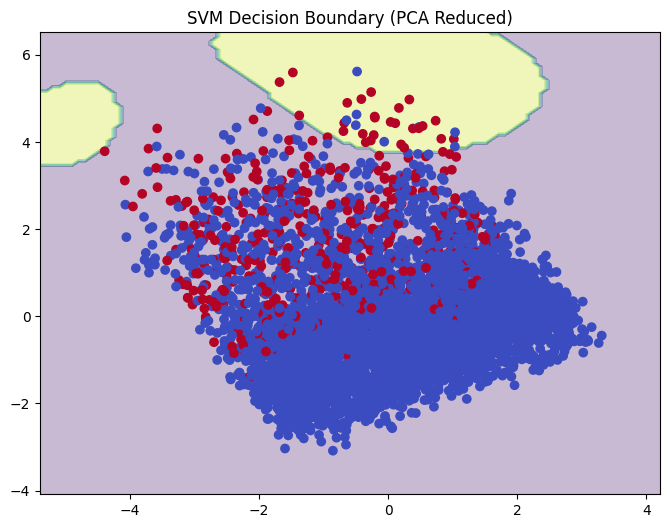

In [58]:
# Train SVM on PCA data
svm_vis = SVC(kernel='rbf')
svm_vis.fit(X_pca, y)

# Meshgrid
import numpy as np

x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = svm_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm')
plt.title("SVM Decision Boundary (PCA Reduced)")
plt.show()

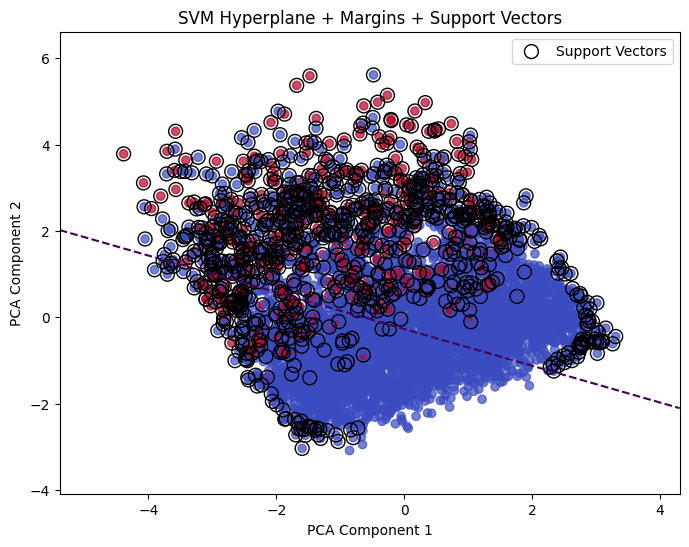

In [59]:
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt

# Use LINEAR kernel to visualize hyperplane
svm_vis = SVC(kernel='linear')
svm_vis.fit(X_pca, y)

# Meshgrid
x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

# Decision function
Z = svm_vis.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(8,6))

# Decision boundary (hyperplane)
plt.contour(xx, yy, Z, levels=[0], linewidths=2)

# Margins
plt.contour(xx, yy, Z, levels=[-1, 1], linestyles='dashed')

# Scatter points
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', alpha=0.7)

# Highlight support vectors
plt.scatter(
    svm_vis.support_vectors_[:,0],
    svm_vis.support_vectors_[:,1],
    s=100,
    facecolors='none',
    edgecolors='k',
    label='Support Vectors'
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("SVM Hyperplane + Margins + Support Vectors")
plt.legend()
plt.show()

In [60]:
from sklearn.tree import DecisionTreeClassifier

# Initialize model
dt_model = DecisionTreeClassifier(random_state=42)

# Train
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [61]:
y_pred_dt = dt_model.predict(X_test)

In [62]:
from sklearn.metrics import accuracy_score

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.982


In [63]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       904
           1       0.88      0.95      0.91        96

    accuracy                           0.98      1000
   macro avg       0.93      0.97      0.95      1000
weighted avg       0.98      0.98      0.98      1000



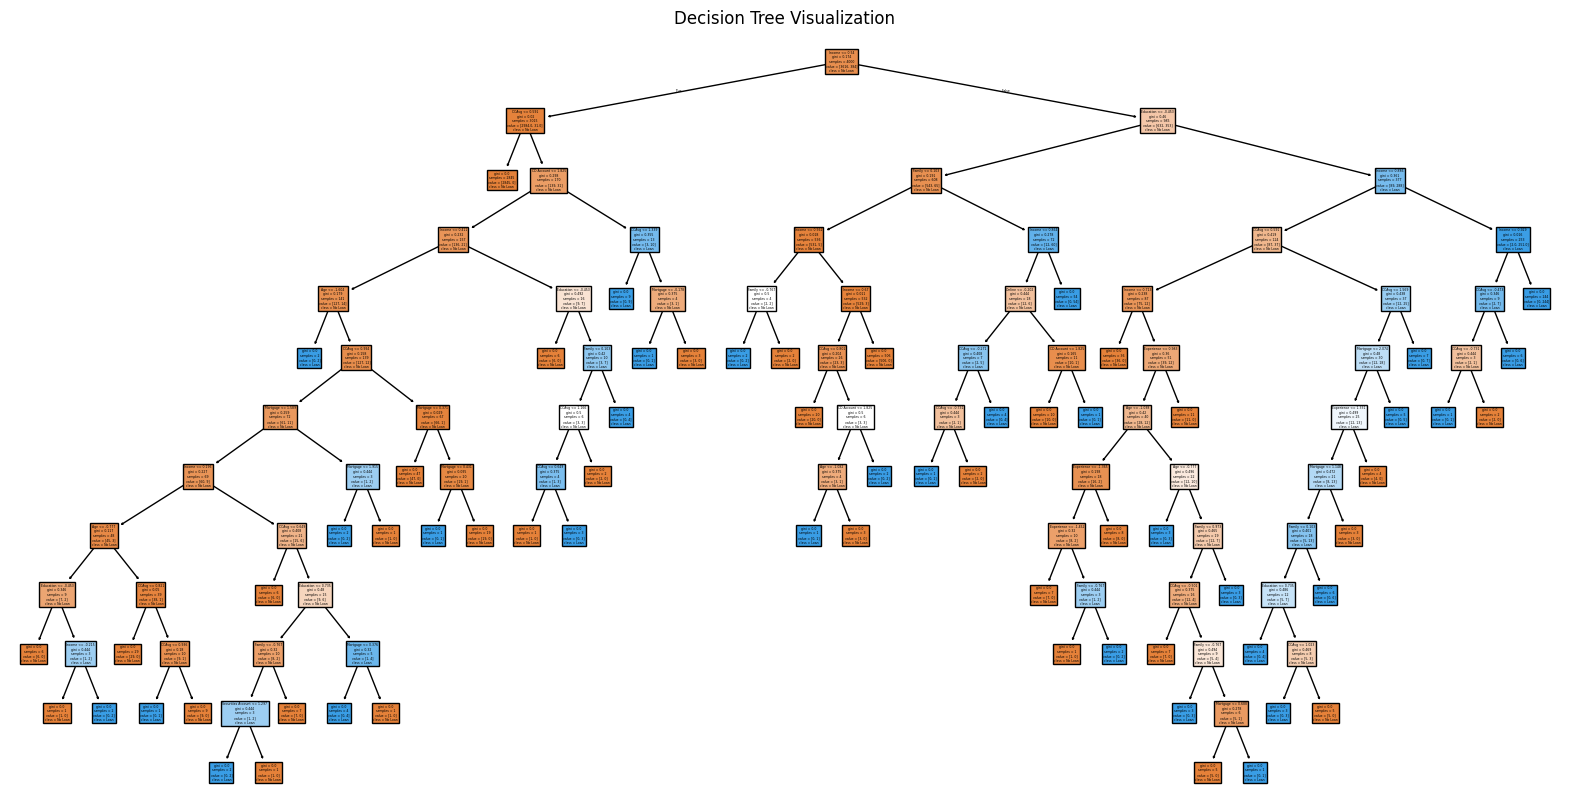

In [64]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=['No Loan', 'Loan'],
    filled=True
)

plt.title("Decision Tree Visualization")
plt.show()

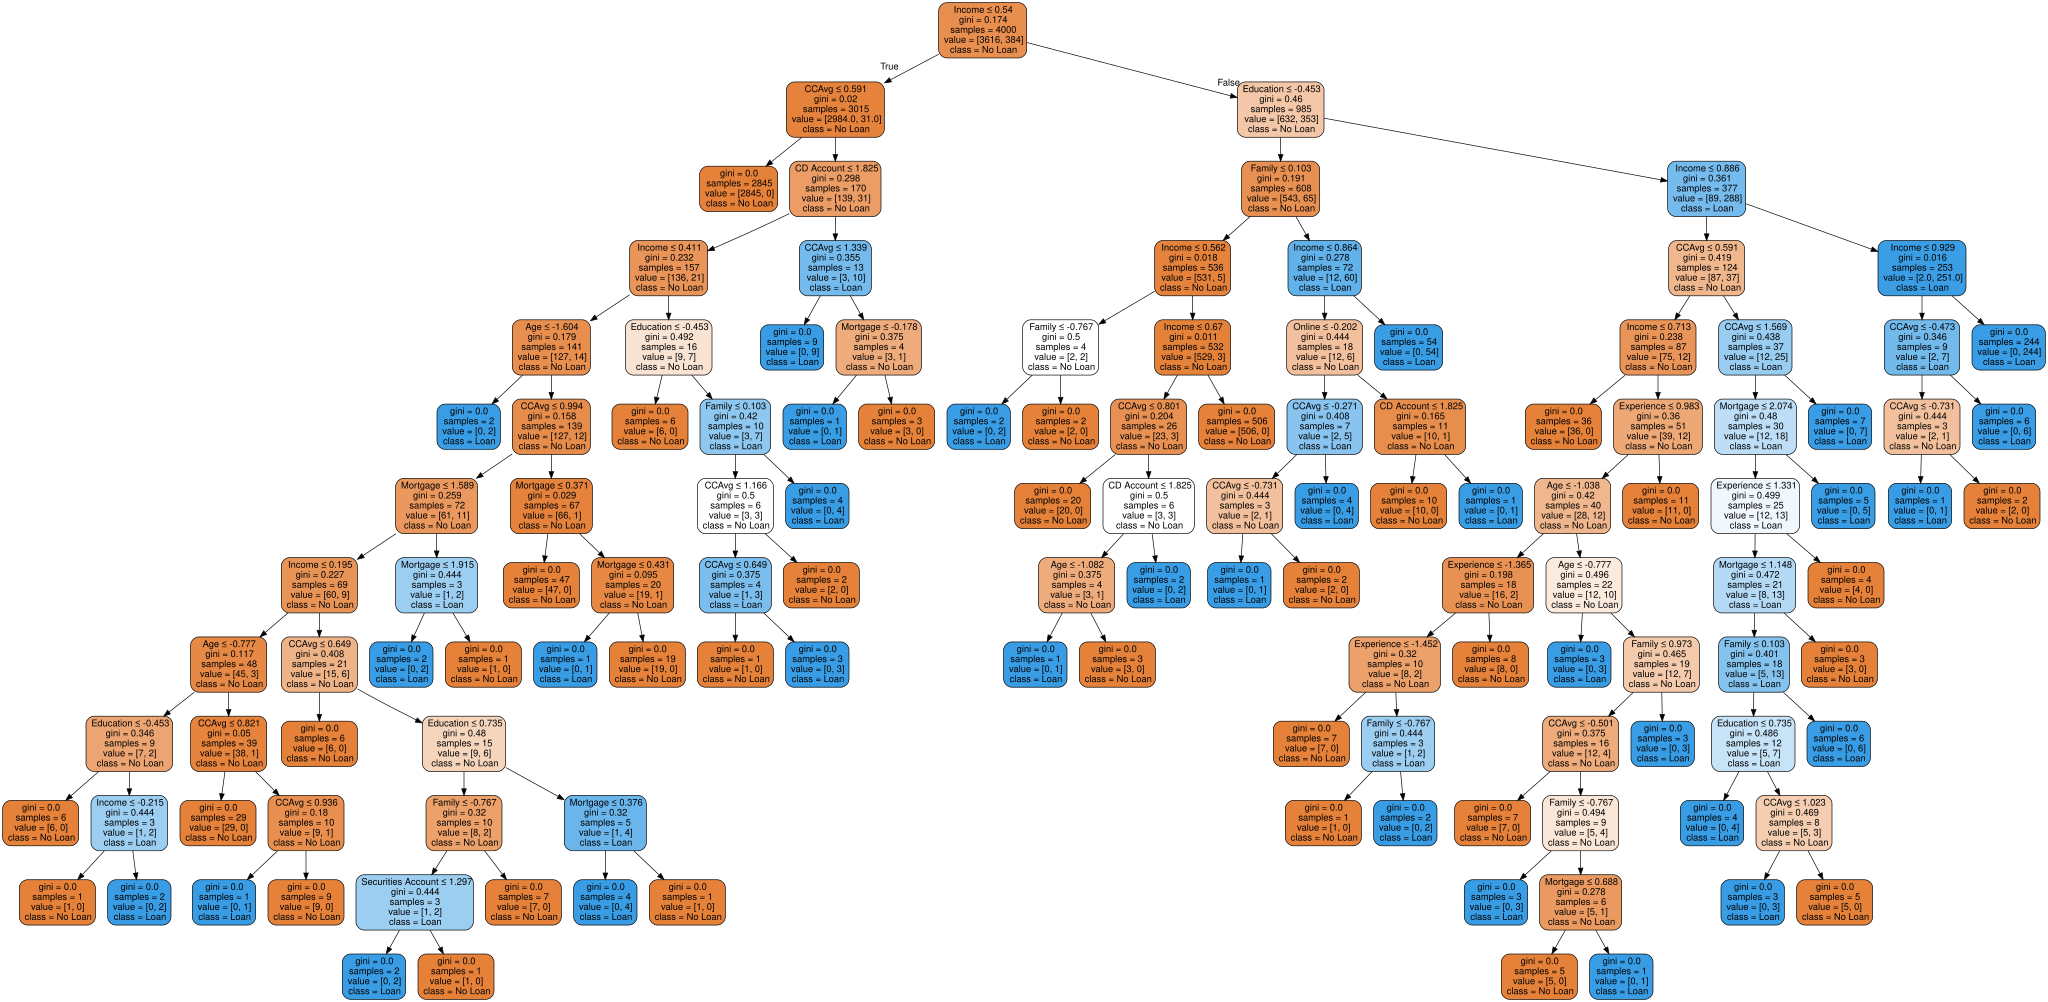

In [65]:
from sklearn.tree import export_graphviz
import graphviz

dot_data = export_graphviz(
    dt_model,
    out_file=None,
    feature_names=X.columns,
    class_names=['No Loan', 'Loan'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = graphviz.Source(dot_data)
graph

In [66]:
dt_model_limited = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

dt_model_limited.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)

In [67]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

importance.sort_values(by='Importance', ascending=False)

,Feature,Importance
2,Income,0.408893
5,Education,0.303688
3,Family,0.143465
4,CCAvg,0.074660
6,Mortgage,0.020635
8,CD Account,0.018746
0,Age,0.014057
1,Experience,0.009147
9,Online,0.004789
7,Securities Account,0.001920


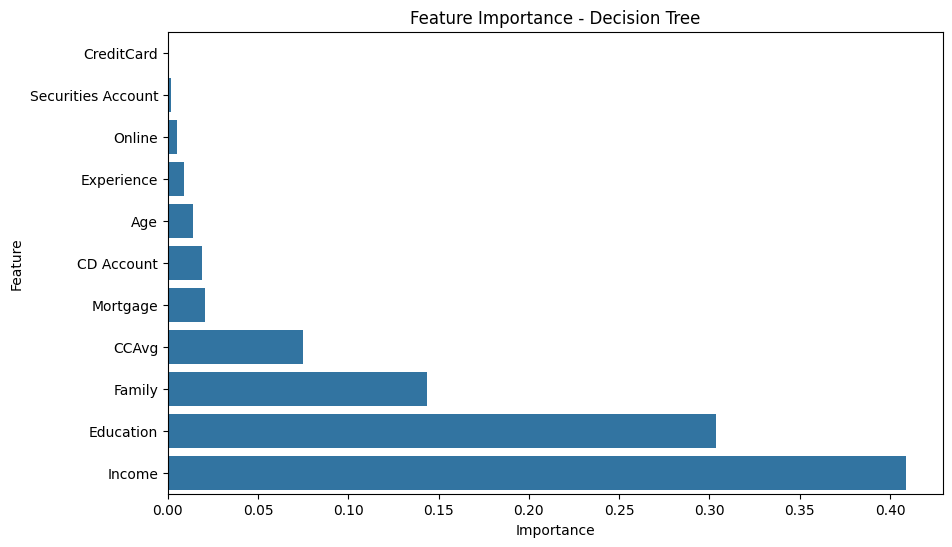

In [68]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance.sort_values(by='Importance')
)

plt.title("Feature Importance - Decision Tree")
plt.show()

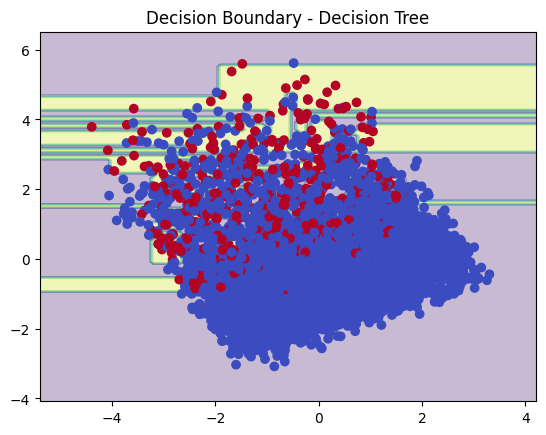

In [69]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

dt_vis = DecisionTreeClassifier()
dt_vis.fit(X_pca, y)

# Meshgrid
import numpy as np

x_min, x_max = X_pca[:,0].min()-1, X_pca[:,0].max()+1
y_min, y_max = X_pca[:,1].min()-1, X_pca[:,1].max()+1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = dt_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm')
plt.title("Decision Boundary - Decision Tree")
plt.show()

| Feature / Aspect            | Logistic Regression 🧠 | Multivariate Logistic 🔁 | SVM ⚡ | Decision Tree 🌳 |
|----------------------------|----------------------|--------------------------|--------|------------------|
| Type                       | Linear Model         | Linear Model             | Linear + Non-linear | Non-linear |
| Input Features             | Single / Multiple    | Multiple                 | Multiple | Multiple |
| Output                     | Probability (0–1)    | Probability (0–1)        | Class label | Class label |
| Decision Boundary          | Linear               | Linear                   | Linear / Non-linear | Non-linear (hierarchical) |
| Interpretability           | High                 | High                     | Low     | Very High |
| Handles Non-linearity      | ❌ No                | ❌ No                    | ✅ Yes  | ✅ Yes |
| Feature Scaling Required   | ✅ Yes               | ✅ Yes                   | ✅ Yes  | ❌ No |
| Handles High Dimensions    | ⚠️ Moderate          | ⚠️ Moderate              | ✅ Excellent | ⚠️ Moderate |
| Overfitting Risk           | Low                  | Low                      | Medium  | High |
| Training Speed             | Fast                 | Fast                     | Slow (large data) | Fast |
| Hyperparameters            | Few                  | Few                      | Many (C, gamma, kernel) | Few (depth, split) |
| Best For                   | Simple problems      | Real-world baseline      | Complex boundaries | Rule-based decisions |
| Visualization              | Easy                 | Moderate (PCA needed)    | Hard (PCA needed) | Very Easy (tree) |
| Robust to Outliers         | ❌ No                | ❌ No                    | ⚠️ Moderate | ⚠️ Moderate |
| Probability Output         | ✅ Yes               | ✅ Yes                   | ⚠️ Limited (needs prob=True) | ❌ No (basic) |
| Real-world Usage           | Baseline model       | Strong baseline          | Advanced ML tasks | Business rules |

## 📌 When to Use What?

👉 Logistic Regression  
- When data is linear  
- Need interpretability  

👉 Multivariate Logistic  
- Real-world baseline model  
- Multiple features involved  

👉 SVM  
- Complex / non-linear data  
- High-dimensional datasets  

👉 Decision Tree  
- Need explainable model  
- Rule-based decisions  